# Implementando Michigrad

In [1]:
#import torch
import numpy as np
from graphviz import Digraph


In [2]:
def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def show_graph(root, format='svg', rankdir='LR'):
    """
    format: png | svg | ...
    rankdir: TB (top to bottom graph) | LR (left to right)
    """
    assert rankdir in ['LR', 'TB']
    nodes, edges = trace(root)
    dot = Digraph(format=format, graph_attr={'rankdir': rankdir}) #, node_attr={'rankdir': 'TB'})
    
    for n in nodes:
        dot.node(name=str(id(n)), label = "{%s | data %.4f | grad %.4f}" % (n.name, n.data, n.grad), shape='record')
        if n._op:
            dot.node(name=str(id(n)) + n._op, label=n._op)
            dot.edge(str(id(n)) + n._op, str(id(n)))
    
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    
    return dot
    
class Value():
    def __init__(self, data, _children=(), _op="", name=""):
        self.data = data
        self.name = name
        self.grad = 0.0
        self._backward = lambda: None
        self._op = _op
        self._prev = set(_children)

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self,other), "+")
        
        def _backward():
            self.grad += out.grad
            other.grad += out.grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self,other), "*")

        def _backward():
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data
        out._backward = _backward
        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "solamente soportamos potencias de int/float"
        out = Value(self.data ** other, _children=(self, ), _op=f"**{other}")

        def _backward():
            self.grad += other * (self.data ** (other - 1)) * out.grad
        out._backward = _backward
        return out

    def __truediv__(self, other):
        return self * other ** -1

    def exp(self):
        out = np.exp(self.data)
        out = Value(out, _children=(self,), _op="exp")
        
        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward       
        return out

    def tanh(self):
        x = self.data
        t = (np.e ** (2*x) - 1)/(np.e ** (2*x) + 1)
        out = Value(t, _children=(self, ), _op="tanh")

        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v is not visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.
        for node in reversed(topo):
            node._backward()

    def __radd__(self, other):
        return self + other

    def __rmul__(self, other):
        return self * other

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def __rsub__(self, other):
        return other + (-self)

    def __repr__(self):
        return f'Value(data={self.data}, grad={self.grad}, _op="{self._op}", name={self.name})'

In [26]:
W0 = Value(-.4, name='W₀')
x0 = Value(.5, name='x₀')
W1 = Value(-.2, name='W₁')
x1 = Value(2, name='x₁')
W0x0 = W0 * x0; W0x0.name = 'W0x0'
W1x1 = W1 * x1; W1x1.name = 'W1x1'
yhat = W0x0 + W1x1; yhat.name = 'ŷ'
yhat = yhat.tanh(); yhat.name = 'tanh(ŷ)'
y = Value(.8, name='y')
L = y - yhat; L.name = 'L'

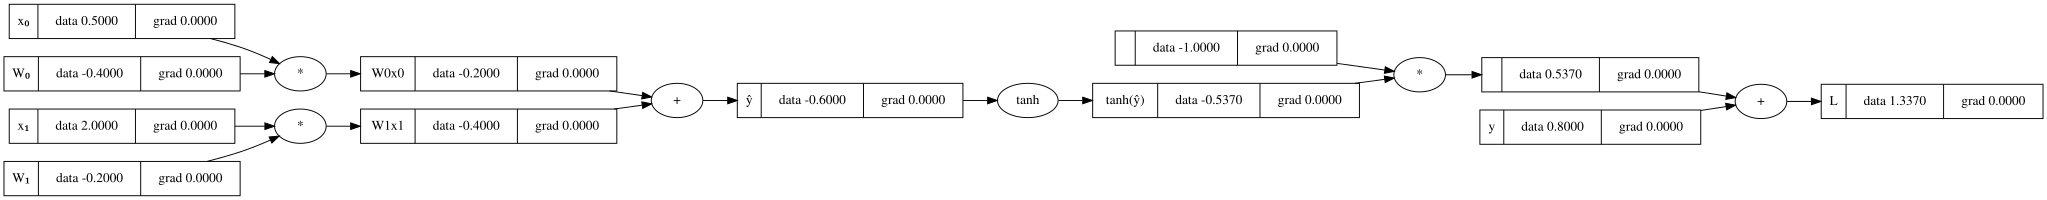

In [27]:
show_graph(L)

In [24]:
L.backward()

In [49]:
class Neuron:
    def __init__(self, nin):
        self.W = [Value(np.random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(np.random.uniform(-1, 1))

    def __call__(self, x):
        act = sum([ws * xs for ws, xs in zip(self.W, x)], self.b)
        return act.tanh()
    
    def params(self):
        return len(self.W) + 1

        
    def parameters(self):
        return self.W + [self.b]

class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        act = [n(x) for n in self.neurons]
        return act

    def params(self):
        return sum([n.params() for n in self.neurons])
    
    def parameters(self):
        return [p for n in self.neurons for p in n.parameters()]


class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for l in self.layers:
            x = l(x)
        return x
    
    def params(self):
        return sum([l.params() for l in self.layers])
    
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [50]:
xs = [[0., 0.],
      [0., 1.],
      [1., 0.],
      [1., 1.]]
ys = [0., 1., 1., 0.]

xor = MLP(2, [3, 3, 1])

yhats = [xor(x) for x in xs]

yhats


[[Value(data=-0.912604080615547, grad=0.0, _op="tanh", name=)],
 [Value(data=-0.9024888022773194, grad=0.0, _op="tanh", name=)],
 [Value(data=-0.9404868159848946, grad=0.0, _op="tanh", name=)],
 [Value(data=-0.9269441590106797, grad=0.0, _op="tanh", name=)]]

In [56]:
loss = sum([(y - yhat[0])**2 for y, yhat in zip(ys, yhats)])/4
loss.backward()

In [57]:
xor.parameters()

[Value(data=-0.9941825985100954, grad=-0.20993005354799438, _op="", name=),
 Value(data=0.7042685292686788, grad=-0.09328166981993558, _op="", name=),
 Value(data=0.575854905589446, grad=-0.22991693387352488, _op="", name=),
 Value(data=-0.2044980099296616, grad=-0.21191006948105537, _op="", name=),
 Value(data=0.3882927849507818, grad=-0.05560567811835349, _op="", name=),
 Value(data=-0.026203683920565712, grad=-0.1275342549811444, _op="", name=),
 Value(data=-0.920568532153216, grad=0.01667644121433995, _op="", name=),
 Value(data=-0.21265669033952683, grad=-0.13701622274453207, _op="", name=),
 Value(data=-0.41489362290620146, grad=-0.2982571108507081, _op="", name=),
 Value(data=0.24127398618988138, grad=-0.05441457612775235, _op="", name=),
 Value(data=-0.10177841631678342, grad=-0.0154831775213225, _op="", name=),
 Value(data=0.8431466644285142, grad=0.05863256923507556, _op="", name=),
 Value(data=-0.7933716097270289, grad=-0.09945289253217478, _op="", name=),
 Value(data=0.4055

In [76]:
np.random.seed(42)
xs = [[1., 0.],
      [0., 0.],
      [0., 1.],
      [1., 1.]]
ys = [0., 1., 1., 0.]
xor = MLP(2, [3, 3, 1])

# definición de hyperparametros
lr = 0.01
steps = 1000

yhats = [xor(x) for x in xs]
yhats

[[Value(data=-0.5955327392762577, grad=0.0, _op="tanh", name=)],
 [Value(data=-0.5804736301685332, grad=0.0, _op="tanh", name=)],
 [Value(data=-0.49737823261722425, grad=0.0, _op="tanh", name=)],
 [Value(data=-0.6173523294670262, grad=0.0, _op="tanh", name=)]]

In [77]:
for step in range(2000):
    # 1. forward pass
    yhats = [xor(x) for x in xs]
    # 2. calculo de la función de perdida
    loss = sum([(y - yhat[0])**2 for y, yhat in zip(ys, yhats)])/4
    # 3. Zero grad
    for p in xor.parameters():
        p.grad = 0.
    # 4. backward pass
    loss.backward()
    # 5. update
    for p in xor.parameters():
        p.data -= p.grad * lr 
loss

Value(data=0.0012830538663251168, grad=1.0, _op="*", name=)

In [78]:
yhats = [xor(x) for x in xs]
yhats

[[Value(data=-0.0012627794725197424, grad=0.0, _op="tanh", name=)],
 [Value(data=0.9495726272373767, grad=0.0, _op="tanh", name=)],
 [Value(data=0.9493269231658267, grad=0.0, _op="tanh", name=)],
 [Value(data=0.004120001737852628, grad=0.0, _op="tanh", name=)]]

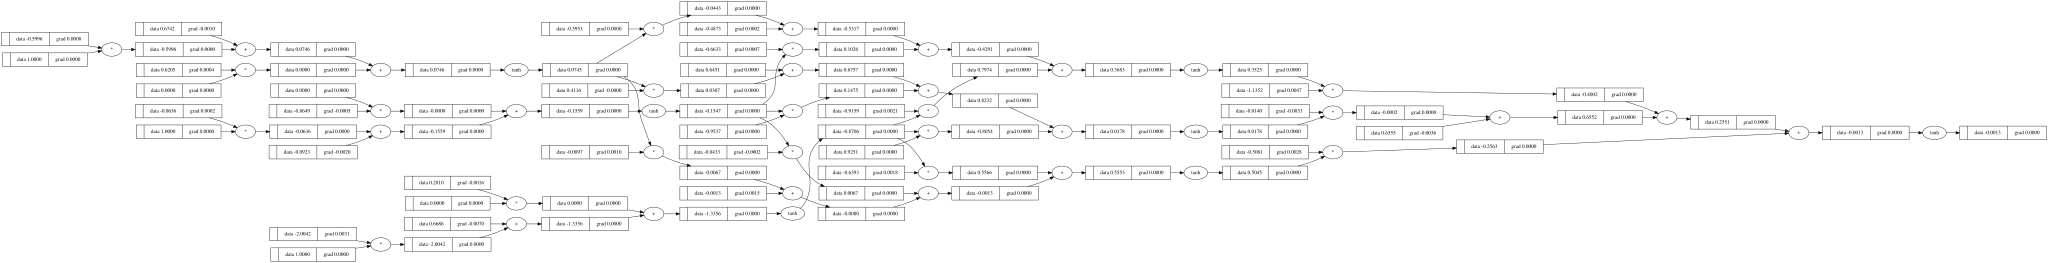

In [80]:
show_graph(yhats[0][0])

## Conclusiones
* Hemos creado una pequeña librería para representar MLPs.
* La librería es suficientemente pontente para representar un clasificador sencillo.
* Es fácil de extender y la interfáz es en su mayor parte compatible con PyTorch.
* Lo visto debería alcanzar para comprender totalmente el código de Michigrad y Micrograd.

## Ejercicios
* Implementar el parámetro `bias` en `Neuron` y `Layer` para poder crear neuronas sin sesgo. (Fácil)
  * Pista: mirar la implementación de Michigrad.
* Implementar el modelo `xor` usando PyTorch. (Fácil si usaste Pytorch antes, Intermedio si no lo hiciste)
  * Pista: PyTorch no implementa un MLP. Se puede redefirnir la clase `MLP` usando `torch.Linear` en lugar de capas de neuronas (`Layer` y `Neuron`).
* Implementar las funciones de activación como capas. (Intermedio)
  * Pista: Reemplazar `Layer` por `Linear`, y definir una clase por cada función de activación. La capa `Linear` se comportará como una capa de neuronas y la capa de activación aplicará la función de activación a cada salida de todas las neuronas de la capa anterior.
* Implementar la clase Module que permita crear modelos como listas de modulos. Todos los módulos deben soportar la `__call__(self, x)` que hace la forward pass.  (Difícil)
  * Pista: Se tendría que poder crear un modelo como una lista de modulos, así:
   ```python
       model = Model([Linear(2, 4), Linear(4, 4, bias=False), Linear(4, 3), Tanh(3)])
       model(x)
   ```